# Assignment 3 – Fashion-MNIST Classification with Neural Networks

**Course:** Machine Learning, NTNU
**Topic:** Simple fully connected neural networks in Keras

**Goal:** build a small baseline neural network for Fashion-MNIST, run three controlled experiments
(changing *one* setting at a time), select the best model **by validation accuracy**, evaluate it once on the
untouched test set, explain how the network is trained, and analyse its errors with a confusion matrix.

**Contents**
1. Setup
2. Load and prepare the data
3. Train / validation split
4. Part A – Build and compare neural networks (Tasks 1–3)
5. Part B – Explain the neural network (Q1–Q4)
6. Part C – Confusion matrix and classification errors
7. Summary

**Fixed settings for every experiment** (as required by the assignment): same training/validation data,
10 epochs, batch size 64, sparse categorical cross-entropy loss, a 10-neuron softmax output layer
and default Keras optimizer settings.

> **Declaration of AI use:** I used an AI assistant (Claude) as a support tool in this assignment –
> to help write and structure the Python code and to help formulate sentences in the explanations.
> I have run the notebook, checked the results and answers, and I am able to explain the code and the results.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
tf.keras.utils.set_random_seed(SEED)       # seeds Python, NumPy and TensorFlow
tf.config.experimental.enable_op_determinism()  # same results every time the notebook is run

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load and prepare the data

Fashion-MNIST contains 70,000 grayscale images of size 28 × 28 in 10 clothing categories
(60,000 for training and 10,000 for testing). The labels are integers 0–9.

The starter code from the assignment normalizes the pixel values from 0–255 to 0–1 and flattens each
image into a vector of 28 × 28 = 784 input features.

In [2]:
# Load Fashion-MNIST
(X_train_full, y_train_full), (X_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

# Normalize pixel values to [0, 1]
X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Flatten 28 x 28 images into 784 features
X_train_full = X_train_full.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Full training data:", X_train_full.shape, y_train_full.shape)
print("Test data:         ", X_test.shape, y_test.shape)
print("Pixel range:        ", X_train_full.min(), "to", X_train_full.max())

Full training data: (60000, 784) (60000,)
Test data:          (10000, 784) (10000,)
Pixel range:         0.0 to 1.0


Quick look at the data: one example image from each class and the class balance.

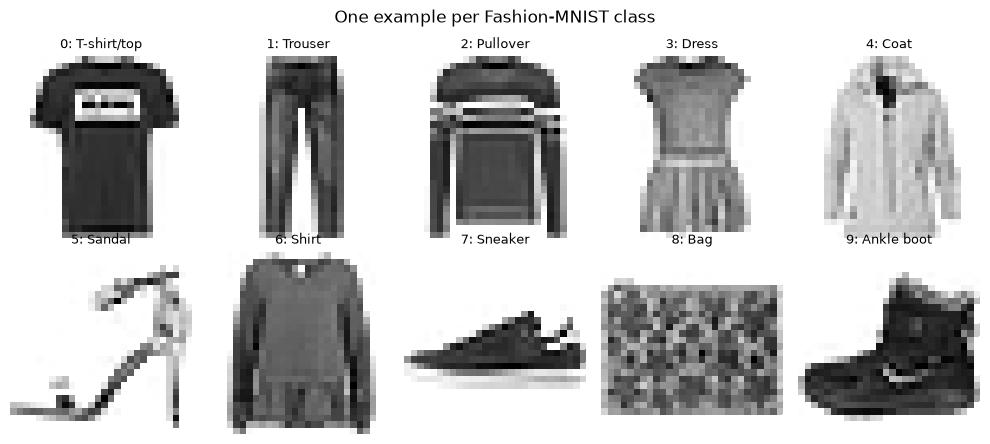

Images per class in the full training data:
T-shirt/top    6000
Trouser        6000
Pullover       6000
Dress          6000
Coat           6000
Sandal         6000
Shirt          6000
Sneaker        6000
Bag            6000
Ankle boot     6000
Name: count, dtype: int64


In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for label, ax in enumerate(axes.ravel()):
    idx = np.where(y_train_full == label)[0][0]
    ax.imshow(X_train_full[idx].reshape(28, 28), cmap="gray_r")
    ax.set_title(f"{label}: {class_names[label]}", fontsize=9)
    ax.axis("off")
plt.suptitle("One example per Fashion-MNIST class")
plt.tight_layout()
plt.show()

print("Images per class in the full training data:")
print(pd.Series(y_train_full).value_counts().sort_index().rename(index=dict(enumerate(class_names))))

## 3. Train / validation split

The test set is kept completely separate and is used **only once**, for the final evaluation of the
selected model. The 60,000 training images are split into:

* **Training set (50,000 images)** – used to learn the weights and biases.
* **Validation set (10,000 images)** – used to compare the four models and choose the best one.

`stratify` keeps the same class proportions in both subsets, and `random_state` makes the split reproducible,
so all four models are trained and validated on exactly the same data.

In [4]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=10_000, stratify=y_train_full, random_state=SEED
)

print("Training:  ", X_train.shape)
print("Validation:", X_val.shape)
print("Test:      ", X_test.shape)

Training:   (50000, 784)
Validation: (10000, 784)
Test:       (10000, 784)


## 4. Part A – Build and compare neural networks

To make the comparison fair, every model is created by the same helper function. Only the three
arguments that the experiments change are exposed: number of hidden neurons, hidden activation and optimizer.
The optimizer is passed as a string (`"adam"` or `"sgd"`), so Keras uses its **default settings**
(learning rate 0.001 for Adam and 0.01 for SGD). The random seed is reset before each model is built, so all
models start from comparable random initial weights and see the batches in the same order.

In [5]:
EPOCHS = 10
BATCH_SIZE = 64


def build_model(hidden_units=32, activation="relu", optimizer="adam"):
    # 784 inputs -> one Dense hidden layer -> 10 softmax outputs
    tf.keras.utils.set_random_seed(SEED)
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(784,)),                         # 784 pixel features
        tf.keras.layers.Dense(hidden_units, activation=activation),
        tf.keras.layers.Dense(10, activation="softmax")       # 10 class probabilities
    ])
    model.compile(
        optimizer=optimizer,                                  # default Keras settings
        loss="sparse_categorical_crossentropy",               # integer labels 0-9
        metrics=["accuracy"]
    )
    return model


def train_model(name, hidden_units=32, activation="relu", optimizer="adam"):
    model = build_model(hidden_units, activation, optimizer)
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0
    )
    train_acc = history.history["accuracy"][-1]
    val_acc = history.history["val_accuracy"][-1]
    print(f"{name:13s} | train acc = {train_acc:.4f} | val acc = {val_acc:.4f}")
    return model, history

### Task 1 – Baseline model

One hidden layer with 32 ReLU neurons, Adam optimizer.

In [6]:
baseline_model, baseline_history = train_model("Baseline", 32, "relu", "adam")
baseline_model.summary()

Baseline      | train acc = 0.8862 | val acc = 0.8736


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,352 (298.25 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 50,902 (198.84 KB)

### Task 2 – Three experiments (one change at a time)

| Model | Hidden neurons | Hidden activation | Optimizer | What changes? |
|---|---|---|---|---|
| Baseline | 32 | ReLU | Adam | – |
| Experiment 1 | **64** | ReLU | Adam | more neurons |
| Experiment 2 | 32 | **tanh** | Adam | activation function |
| Experiment 3 | 32 | ReLU | **SGD** | optimizer |

In [7]:
experiments = {
    "Experiment 1": dict(hidden_units=64, activation="relu", optimizer="adam"),
    "Experiment 2": dict(hidden_units=32, activation="tanh", optimizer="adam"),
    "Experiment 3": dict(hidden_units=32, activation="relu", optimizer="sgd"),
}

models = {"Baseline": baseline_model}
histories = {"Baseline": baseline_history}
configs = {"Baseline": dict(hidden_units=32, activation="relu", optimizer="adam")}

for name, cfg in experiments.items():
    models[name], histories[name] = train_model(name, **cfg)
    configs[name] = cfg

Experiment 1  | train acc = 0.8978 | val acc = 0.8759


Experiment 2  | train acc = 0.8916 | val acc = 0.8842


Experiment 3  | train acc = 0.8476 | val acc = 0.8515


### Task 3 – Results table and model selection

The training and validation accuracy are taken from the **last (10th) epoch**. Note that Keras reports the
training accuracy as the average over the batches of the final epoch, while the validation accuracy is
computed after the epoch with the final weights.

In [8]:
rows = []
for name, hist in histories.items():
    cfg = configs[name]
    rows.append({
        "Model": name,
        "Hidden neurons": cfg["hidden_units"],
        "Hidden activation": "ReLU" if cfg["activation"] == "relu" else cfg["activation"],
        "Optimizer": "Adam" if cfg["optimizer"] == "adam" else cfg["optimizer"].upper(),
        "Trainable params": models[name].count_params(),
        "Train accuracy": hist.history["accuracy"][-1],
        "Validation accuracy": hist.history["val_accuracy"][-1],
    })

results = pd.DataFrame(rows).set_index("Model")
results["Train - val gap"] = results["Train accuracy"] - results["Validation accuracy"]
results.style.format({"Train accuracy": "{:.4f}", "Validation accuracy": "{:.4f}",
                      "Train - val gap": "{:+.4f}", "Trainable params": "{:,}"}) \
       .highlight_max(subset=["Validation accuracy"], color="lightgreen")

,Hidden neurons,Hidden activation,Optimizer,Trainable params,Train accuracy,Validation accuracy,Train - val gap
Model,,,,,,,
Baseline,32,ReLU,Adam,"25,450",0.8862,0.8736,+0.0126
Experiment 1,64,ReLU,Adam,"50,890",0.8978,0.8759,+0.0219
Experiment 2,32,tanh,Adam,"25,450",0.8916,0.8842,+0.0074
Experiment 3,32,ReLU,SGD,"25,450",0.8476,0.8515,-0.0039


In [9]:
best_name = results["Validation accuracy"].idxmax()
best_model = models[best_name]
print(f"Selected model (highest validation accuracy): {best_name}")
print(f"Validation accuracy: {results.loc[best_name, 'Validation accuracy']:.4f}")

Selected model (highest validation accuracy): Experiment 2
Validation accuracy: 0.8842


Learning curves for all four models (the test set is not involved here):

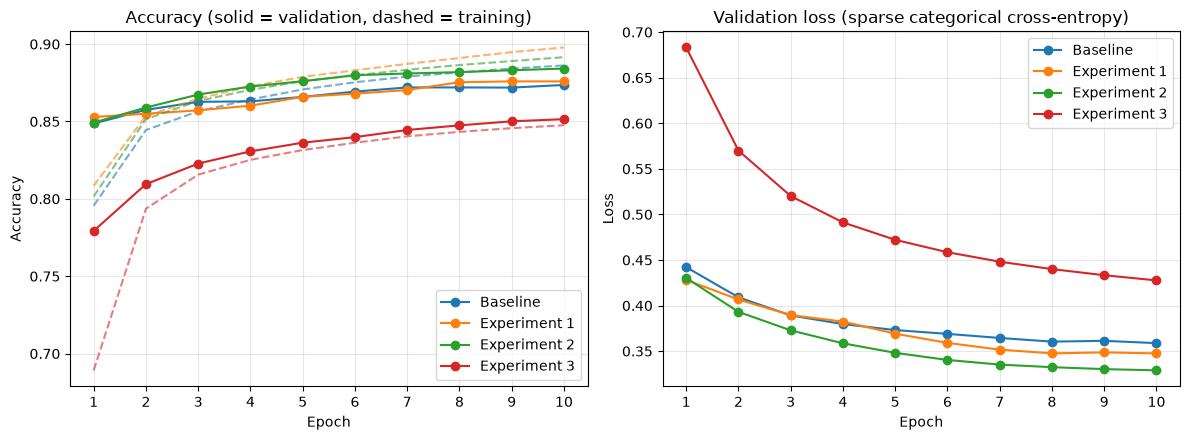

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
epochs = range(1, EPOCHS + 1)
for name, hist in histories.items():
    line, = axes[0].plot(epochs, hist.history["val_accuracy"], marker="o", label=name)
    axes[0].plot(epochs, hist.history["accuracy"], linestyle="--", color=line.get_color(), alpha=0.6)
    axes[1].plot(epochs, hist.history["val_loss"], marker="o", label=name)

axes[0].set_title("Accuracy (solid = validation, dashed = training)")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy"); axes[0].legend()
axes[1].set_title("Validation loss (sparse categorical cross-entropy)")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss"); axes[1].legend()
for ax in axes:
    ax.set_xticks(list(epochs)); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Final evaluation of the selected model on the test set

The model was chosen using **only** the validation accuracy above. The test set is now used once to estimate
how well the selected model generalizes to completely new images.

In [11]:
test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print(f"Selected model: {best_name}")
print(f"Test loss:      {test_loss:.4f}")
print(f"Test accuracy:  {test_acc:.4f}  ({test_acc:.2%})")

Selected model: Experiment 2
Test loss:      0.3741
Test accuracy:  0.8671  (86.71%)


## 5. Part B – Explain the neural network

### Q1. Architecture and parameters

The baseline network is **784 → 32 → 10**. Each `Dense` neuron has one weight per incoming connection and one bias.

| Layer | Weights | Biases | Total |
|---|---|---|---|
| Input → hidden | 784 × 32 = **25,088** | 32 | 25,120 |
| Hidden → output | 32 × 10 = **320** | 10 | 330 |
| **Total** | **25,408** | **42** | **25,450** |

So the baseline model has **25,408 weights + 42 biases = 25,450 trainable parameters**
(the cell below confirms this with Keras).

A **parameter** is a value the model *learns* from the training data – the weights and biases, which are
updated by the optimizer during `fit()`. A **hyperparameter** is a setting *I choose before training* that
controls the model or the training process, such as the number of hidden neurons, the activation function,
the optimizer and learning rate, the batch size and the number of epochs. Hyperparameters are not learned by
gradient descent; I chose between them by comparing validation performance, as in Part A.

In [12]:
weights = sum(int(np.prod(w.shape)) for w in baseline_model.trainable_weights if len(w.shape) == 2)
biases = sum(int(np.prod(w.shape)) for w in baseline_model.trainable_weights if len(w.shape) == 1)
print(f"Weights: {weights:,} | Biases: {biases:,} | Total: {baseline_model.count_params():,}")

Weights: 25,408 | Biases: 42 | Total: 25,450


### Q2. Activation and loss

**ReLU in the hidden layer:** each hidden neuron computes a weighted sum z = Σ wᵢxᵢ + b and then applies
ReLU, a = max(0, z). The activation must be *nonlinear*; without it, stacking Dense layers would still give a
linear model that cannot learn complex patterns in the pixels. ReLU is a good default because it is cheap to
compute and does not saturate for positive values, so gradients stay large and training is fast.

**Softmax in the output layer:** the 10 output neurons produce arbitrary scores (logits), one per clothing
class. Softmax, pₖ = e^{sₖ} / Σⱼ e^{sⱼ}, turns them into 10 probabilities between 0 and 1 that sum to 1, and the
predicted class is the one with the largest probability.

**Sparse categorical cross-entropy:** this is a multiclass problem (10 mutually exclusive classes) and the
labels are stored as integers 0–9, not one-hot vectors – that is what "sparse" means. The loss for one image is
L = −ln(p_actual), the negative log of the probability given to the correct class, so it is small when the model
is confident and correct and very large when it is confident and wrong.

### Q3. Training and Keras functions

* **`model.compile()`** configures the model for training: it sets the **loss function** (what counts as error),
  the **optimizer** (how the weights are updated) and the **metrics** to report (here accuracy).
* **`model.fit()`** trains the model: for every batch of 64 images it runs the forward pass, computes the loss,
  uses backpropagation to compute the gradients and lets the optimizer update the weights – repeated for 10 epochs.
  With `validation_data` it also reports validation loss/accuracy after each epoch.
* **`model.evaluate()`** computes the loss and metrics on a given dataset (here the test set) **without**
  changing the weights.
* **`model.predict()`** returns the softmax output – 10 class probabilities for each image; `np.argmax`
  gives the predicted class.

**Backpropagation** works backwards from the loss through the network and uses the chain rule to calculate the
gradient ∂L/∂w for every weight and bias, i.e. how the loss would change if that parameter changed slightly.
The **optimizer** then uses these gradients to update the parameters in the direction that lowers the loss,
e.g. plain gradient descent: w_new = w_old − η · ∂L/∂w. SGD uses a fixed learning rate η, while Adam adapts the
step size for each parameter using the history of its gradients.

The cell below demonstrates `predict()` on one test image.

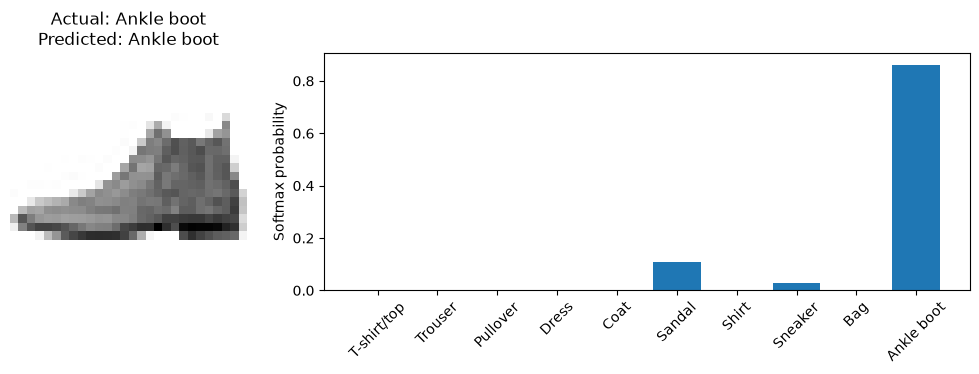

Sum of the 10 probabilities: 1.0


In [13]:
probabilities = best_model.predict(X_test[:1], verbose=0)[0]
predicted = int(np.argmax(probabilities))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={"width_ratios": [1, 2.5]})
axes[0].imshow(X_test[0].reshape(28, 28), cmap="gray_r")
axes[0].set_title(f"Actual: {class_names[y_test[0]]}\nPredicted: {class_names[predicted]}")
axes[0].axis("off")
axes[1].bar(class_names, probabilities)
axes[1].set_ylabel("Softmax probability")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

print("Sum of the 10 probabilities:", round(float(probabilities.sum()), 4))

### Q4. Interpreting the experiments


| Model | Change vs. baseline | Train acc. | Validation acc. | Δ val. vs. baseline |
|---|---|---|---|---|
| Baseline | – | 0.8862 | 0.8736 | – |
| Experiment 1 | 64 neurons | 0.8978 | 0.8759 | +0.0023 |
| **Experiment 2** | **tanh** | 0.8916 | **0.8842** | **+0.0106** |
| Experiment 3 | SGD | 0.8476 | 0.8515 | −0.0221 |

**Experiment 2 (tanh) achieved the highest validation accuracy (0.8842)** and reached a test accuracy of
**0.8671**. The changes did **not** always help: 64 neurons raised training accuracy by 1.2 points but validation
accuracy by only 0.2, so the extra capacity mostly widened the train–validation gap. SGD with its default
learning rate learns more slowly than Adam and was still under-fitting after 10 epochs (−2.2 points).
The differences between the Adam models are small and come from one run, so each setting must be checked
on validation data rather than assumed to improve the model.

## 6. Part C – Understanding classification errors

The confusion matrix below is computed for the **selected model on the test set**. Rows are the actual
classes, columns are the predicted classes; the diagonal holds the correct predictions.

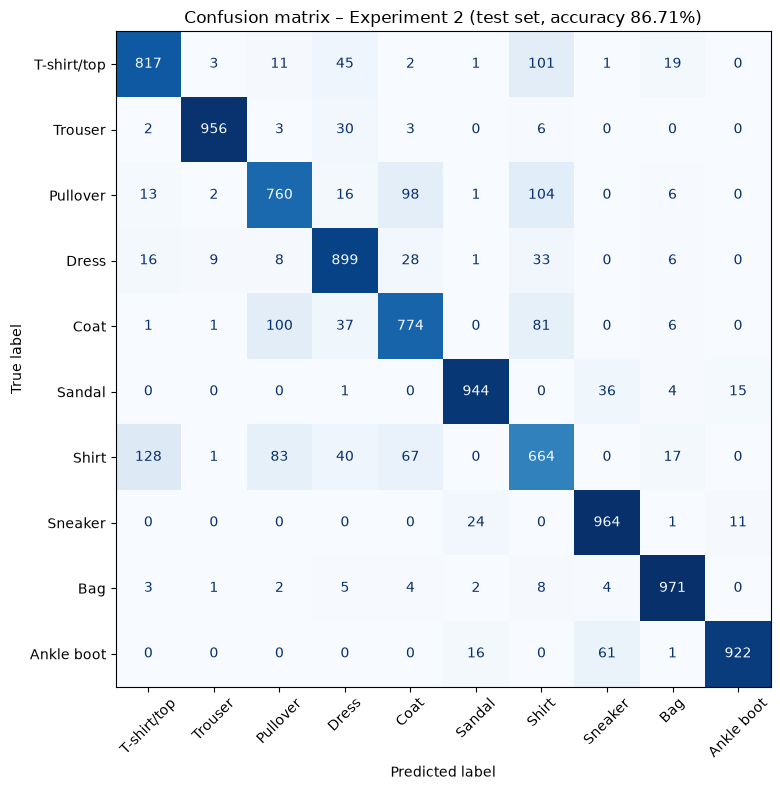

In [14]:
y_pred = np.argmax(best_model.predict(X_test, verbose=0), axis=1)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False, values_format="d"
)
ax.set_title(f"Confusion matrix – {best_name} (test set, accuracy {test_acc:.2%})")
plt.tight_layout()
plt.show()

Per-class accuracy (recall) and the most frequent confusions:

In [15]:
per_class = pd.DataFrame({
    "Correct": np.diag(cm),
    "Total": cm.sum(axis=1),
    "Per-class accuracy": np.diag(cm) / cm.sum(axis=1),
}, index=class_names).sort_values("Per-class accuracy")
display(per_class.style.format({"Per-class accuracy": "{:.1%}"}))

off_diag = cm.copy()
np.fill_diagonal(off_diag, 0)
pairs = [(class_names[i], class_names[j], off_diag[i, j])
         for i in range(10) for j in range(10) if off_diag[i, j] > 0]
top_confusions = pd.DataFrame(pairs, columns=["Actual", "Predicted as", "Count"]) \
    .sort_values("Count", ascending=False).head(6).reset_index(drop=True)
top_confusions

,Correct,Total,Per-class accuracy
Shirt,664,1000,66.4%
Pullover,760,1000,76.0%
Coat,774,1000,77.4%
T-shirt/top,817,1000,81.7%
Dress,899,1000,89.9%
Ankle boot,922,1000,92.2%
Sandal,944,1000,94.4%
Trouser,956,1000,95.6%
Sneaker,964,1000,96.4%
Bag,971,1000,97.1%


,Actual,Predicted as,Count
0,Shirt,T-shirt/top,128
1,Pullover,Shirt,104
2,T-shirt/top,Shirt,101
3,Coat,Pullover,100
4,Pullover,Coat,98
5,Shirt,Pullover,83


Examples of the most common mistake:

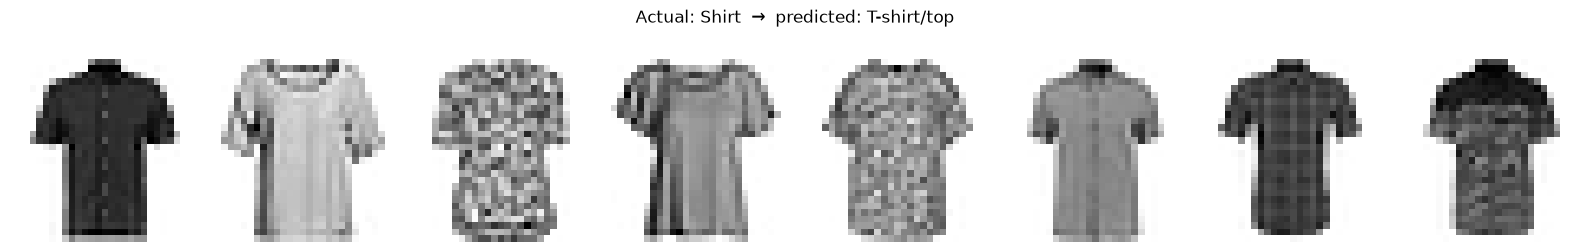

In [16]:
actual_label = class_names.index(top_confusions.loc[0, "Actual"])
predicted_label = class_names.index(top_confusions.loc[0, "Predicted as"])
wrong_idx = np.where((y_test == actual_label) & (y_pred == predicted_label))[0][:8]

fig, axes = plt.subplots(1, len(wrong_idx), figsize=(2 * len(wrong_idx), 2.6))
for ax, idx in zip(np.atleast_1d(axes), wrong_idx):
    ax.imshow(X_test[idx].reshape(28, 28), cmap="gray_r")
    ax.axis("off")
plt.suptitle(f"Actual: {class_names[actual_label]}  →  predicted: {class_names[predicted_label]}")
plt.tight_layout()
plt.show()

### Interpretation


The most frequent mistakes are between the upper-body garments. **Shirt and T-shirt/top are the pair the model
confuses the most:** 128 shirts were predicted as T-shirt/top and 101 T-shirts/tops as shirts. As 28 × 28
grayscale silhouettes they have almost the same shape, and the details that separate them (collar, buttons,
sleeve length) are only a few pixels. Pullover ↔ Coat (100 and 98 errors) and Pullover → Shirt (104) are similar
cases, while classes with a unique shape – Bag, Sneaker, Trouser, Sandal – are recognised more than 94 % of the time.

**What the confusion matrix shows that overall accuracy does not:** the overall test accuracy of 86.7 % is a single
average over all classes and hides how unevenly the errors are spread. The confusion matrix shows *which* classes
are hard (Shirt is correct only 66.4 % of the time, Bag 97.1 %) and *which classes are mixed up with each other*,
so I can see that the errors are not random but are systematic confusions between visually similar clothing.

## 7. Summary


* A simple fully connected network (784 → 32 → 10) reaches about **87–88 % accuracy** on Fashion-MNIST after
  10 epochs.
* Of the four models, **Experiment 2 (32 tanh neurons, Adam)** had the highest validation accuracy (0.8842) and
  was selected *without* looking at the test set. Its **test accuracy is 0.8671 (86.71 %)**.
* More neurons gave a small validation gain but a larger train–validation gap; SGD with default settings
  under-fitted in 10 epochs; tanh worked slightly better than ReLU for this shallow network.
* The confusion matrix shows that most errors come from visually similar upper-body garments
  (Shirt ↔ T-shirt/top, Pullover ↔ Coat ↔ Shirt), something the overall accuracy alone cannot reveal.